# Umbrella OPEN/CLOSED labels

Loads the simulated weather from `simulated_dataset/` and adds a `label` column (`OPEN`/`CLOSED`) with its probability `p_open`.

Two independent reasons open the umbrella:

- **Heat:** pythermalcomfort's UTCI (Universal Thermal Climate Index), from temperature, humidity and wind, averaged over the past few minutes and turned into `p_heat` with an S-shaped (logistic) curve.
  It's about 5% at the start of *moderate heat stress* (UTCI 26 °C), 50% at 29 °C and 95% at *strong heat stress* (32 °C).
  Heat only counts during daytime hours.
- **Rain:** `p_rain` is 100% while the rain gauge measures rain or the precipitation detector (`rain_flag`) is on, then fades over a few minutes.

`p_open = 1 − (1 − p_heat)(1 − p_rain)`: the chance that at least one reason applies.
The label opens at `p_open ≥ THRESHOLD` and closes only once `p_open < CLOSE_THRESHOLD`, so it doesn't flap open and closed.

**Limitation:** the station's solar radiation column is empty, so UTCI treats the radiant temperature as equal to the air temperature, i.e. heat stress in the shade.
That underestimates heat in direct sun.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pythermalcomfort.models import utci

from modules.dataset.dataset import load_aws

## 1. Load the simulated dataset

`rain_flag` (the precipitation detector) catches drizzle and the start of showers that the 0.5 mm rain gauge misses.
If the simulated files don't have it, it's taken from the raw `dataset/` files: each row gets the flag of the minute it falls in.
KMA labels a minute by its end, so row `t` belongs to the minute labeled `floor(t) + 1 min`.

In [2]:
SIM_DIR = Path("simulated_dataset")

files = sorted(SIM_DIR.glob("*.csv"))
weather = pd.concat(
    (pd.read_csv(f, index_col="timestamp", parse_dates=["timestamp"]) for f in files)
).sort_index()

if "rain_flag" not in weather:
    raw = load_aws("dataset").set_index("timestamp")
    minute = weather.index.floor("min") + pd.Timedelta(minutes=1)
    weather["rain_flag"] = raw["rain_flag"].reindex(minute).fillna(0.0).to_numpy()

print(f"{len(files)} files, {len(weather):,} rows, {weather.index.min()} → {weather.index.max()}")
weather.head()

19 files, 2,385,742 rows, 2024-01-01 00:01:00 → 2026-07-07 23:58:40


,temperature,pressure,sea_pressure,humidity,wind_speed,rain,wind_dir,wind_u,wind_v,rain_flag
timestamp,,,,,,,,,,
2024-01-01 00:01:00,0.700000,1018.8,1025.100000,96.0,0.634568,0.0,48.166641,-0.472809,-0.423235,0.0
2024-01-01 00:01:20,0.723457,1018.8,1025.100000,96.0,0.634568,0.0,47.561591,-0.468313,-0.428205,0.0
2024-01-01 00:01:40,0.758025,1018.8,1025.100000,96.0,0.530864,0.0,53.760634,-0.428171,-0.313826,0.0
2024-01-01 00:02:00,0.800000,1018.8,1025.100000,96.0,0.246914,0.0,70.314724,-0.232483,-0.083174,0.0
2024-01-01 00:02:20,0.871605,1018.8,1025.074074,96.0,0.143210,0.0,76.511896,-0.139260,-0.033403,0.0


## 2. Configure

In [3]:
THRESHOLD = 0.5            # open when p_open >= THRESHOLD
CLOSE_THRESHOLD = 0.3      # once open, close only when p_open < CLOSE_THRESHOLD
UTCI_SMOOTH_MINUTES = 10   # heat uses the trailing mean UTCI over this many minutes
HEAT_CENTER = 29.0         # UTCI (°C) where p_heat = 50%
HEAT_WIDTH = 1.02          # logistic width: 26 °C → 5%, 32 °C → 95%
HEAT_HOURS = (7, 19)       # local hours [start, end) when heat counts; None = all day
RAIN_DECAY_MINUTES = 5.0   # p_rain fades to 37% after 5 min, 14% after 10 min

## 3. Heat: UTCI → `p_heat`

UTCI needs air temperature, mean radiant temperature, wind speed at 10 m and humidity.
Wind is clipped to 0.5–17 m/s, the range UTCI is defined for.

In [4]:
tdb = weather["temperature"].to_numpy()
thermal = utci(
    tdb=tdb,
    tr=tdb,  # no solar radiation data: shade
    v=weather["wind_speed"].clip(0.5, 17.0).to_numpy(),
    rh=weather["humidity"].clip(0.0, 100.0).to_numpy(),
    limit_inputs=False, round_output=False,
)
utci_value = pd.Series(thermal.utci, index=weather.index)
utci_smooth = utci_value.rolling(pd.Timedelta(minutes=UTCI_SMOOTH_MINUTES)).mean()

p_heat = 1.0 / (1.0 + np.exp(-(utci_smooth - HEAT_CENTER) / HEAT_WIDTH))
if HEAT_HOURS is not None:
    hour = weather.index.hour
    p_heat = p_heat.where((hour >= HEAT_HOURS[0]) & (hour < HEAT_HOURS[1]), 0.0)

## 4. Rain → `p_rain`

100% while wet, then `exp(-minutes since last wet row / RAIN_DECAY_MINUTES)`.

In [5]:
wet = (weather["rain"] > 0) | (weather["rain_flag"] > 0)
times = weather.index.to_series()
minutes_since_wet = (times - times.where(wet).ffill()).dt.total_seconds() / 60.0
p_rain = np.exp(-minutes_since_wet / RAIN_DECAY_MINUTES).fillna(0.0)

## 5. Add the label columns

- `p_open`: probability that the umbrella should be open, `1 − (1 − p_heat)(1 − p_rain)`
- `open_percent`: the same probability as a percentage, 0–100
- `label`: `OPEN`/`CLOSED`, with hysteresis between `THRESHOLD` and `CLOSE_THRESHOLD`
- `reason`: `heat`, `rain` or `heat+rain` for open rows; empty when closed

In [6]:
p_open = 1.0 - (1.0 - p_heat) * (1.0 - p_rain)

# 1 above the open threshold, 0 below the close threshold, otherwise keep the previous state
state = pd.Series(np.nan, index=weather.index)
state[p_open >= THRESHOLD] = 1.0
state[p_open < CLOSE_THRESHOLD] = 0.0
is_open = state.ffill().fillna(0.0).astype(bool)

both = (p_heat >= CLOSE_THRESHOLD) & (p_rain >= CLOSE_THRESHOLD)
reason = np.select([both, p_rain >= p_heat], ["heat+rain", "rain"], "heat")

labeled = weather.assign(
    utci=utci_value,
    utci_smooth=utci_smooth,
    stress_category=thermal.stress_category,
    p_heat=p_heat,
    p_rain=p_rain,
    p_open=p_open,
    open_percent=(100 * p_open).round(1),
    label=np.where(is_open, "OPEN", "CLOSED"),
    reason=np.where(is_open, reason, ""),
)

print(labeled["label"].value_counts(normalize=True).map("{:.1%}".format).to_string())
print(labeled.loc[is_open, "reason"].value_counts(normalize=True).map("{:.1%}".format).to_string())
switches = int(is_open.astype(int).diff().abs().sum())
print(f"{switches:,} open/close switches, {switches / labeled.index.normalize().nunique():.1f} per day")
labeled[["temperature", "humidity", "wind_speed", "rain", "rain_flag",
         "utci", "p_heat", "p_rain", "open_percent", "label", "reason"]].head()

label
CLOSED    86.3%
OPEN      13.7%
reason
rain         55.0%
heat         43.4%
heat+rain     1.6%
2,478 open/close switches, 4.5 per day


,temperature,humidity,wind_speed,rain,rain_flag,utci,p_heat,p_rain,open_percent,label,reason
timestamp,,,,,,,,,,,
2024-01-01 00:01:00,0.700000,96.0,0.634568,0.0,0.0,1.934163,0.0,0.0,0.0,CLOSED,
2024-01-01 00:01:20,0.723457,96.0,0.634568,0.0,0.0,1.959623,0.0,0.0,0.0,CLOSED,
2024-01-01 00:01:40,0.758025,96.0,0.530864,0.0,0.0,2.278381,0.0,0.0,0.0,CLOSED,
2024-01-01 00:02:00,0.800000,96.0,0.246914,0.0,0.0,2.404824,0.0,0.0,0.0,CLOSED,
2024-01-01 00:02:20,0.871605,96.0,0.143210,0.0,0.0,2.481504,0.0,0.0,0.0,CLOSED,


## 6. Share of time open, by month

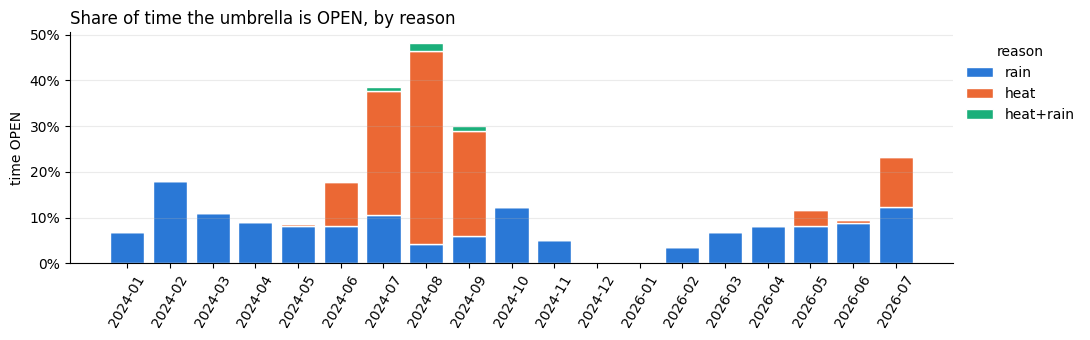

In [7]:
reasons = ["rain", "heat", "heat+rain"]
monthly = pd.crosstab(labeled.index.to_period("M"), labeled["reason"], normalize="index")
monthly = monthly.reindex(columns=reasons, fill_value=0.0)

COLORS = {"rain": "#2a78d6", "heat": "#eb6834", "heat+rain": "#1baf7a"}
fig, ax = plt.subplots(figsize=(11, 3.5))
bottom = np.zeros(len(monthly))
x = monthly.index.astype(str)
for r in reasons:
    ax.bar(x, monthly[r], bottom=bottom, color=COLORS[r], label=r,
           width=0.8, edgecolor="white", linewidth=1)
    bottom += monthly[r].to_numpy()
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_ylabel("time OPEN")
ax.tick_params(axis="x", rotation=60)
ax.grid(axis="y", alpha=0.25)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(title="reason", frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title("Share of time the umbrella is OPEN, by reason", loc="left")
fig.tight_layout()

## 7. One day in detail

Shows the day with the most time open for both heat and rain. Set `DAY` to any date to inspect it instead.

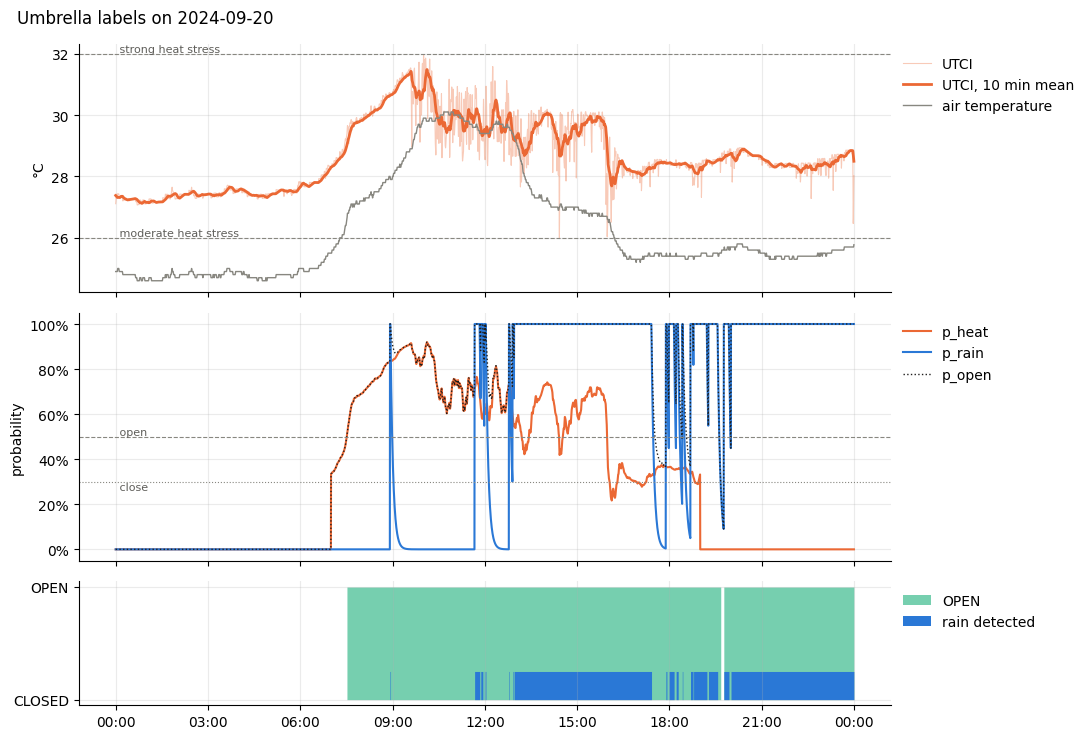

In [8]:
DAY = None   # e.g. "2024-07-15"

if DAY is None:
    daily = labeled.groupby(labeled.index.date)["reason"].agg(
        heat=lambda r: r.str.contains("heat").sum(), rain=lambda r: r.str.contains("rain").sum())
    DAY = str(daily.min(axis=1).idxmax())
day = labeled.loc[DAY]

fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True,
                         gridspec_kw={"height_ratios": [2, 2, 1]})
ax = axes[0]
ax.plot(day.index, day["utci"], color="#eb6834", lw=0.8, alpha=0.35, label="UTCI")
ax.plot(day.index, day["utci_smooth"], color="#eb6834", lw=2, label=f"UTCI, {UTCI_SMOOTH_MINUTES} min mean")
ax.plot(day.index, day["temperature"], color="#888780", lw=1, label="air temperature")
for level, name in [(26, "moderate heat stress"), (32, "strong heat stress")]:
    ax.axhline(level, color="#888780", lw=0.8, ls="--")
    ax.text(day.index[0], level, f" {name}", va="bottom", fontsize=8, color="#5f5e5a")
ax.set_ylabel("°C")

ax = axes[1]
ax.plot(day.index, day["p_heat"], color="#eb6834", lw=1.5, label="p_heat")
ax.plot(day.index, day["p_rain"], color="#2a78d6", lw=1.5, label="p_rain")
ax.plot(day.index, day["p_open"], color="#1f1e1d", lw=1, ls=":", label="p_open")
ax.axhline(THRESHOLD, color="#888780", lw=0.8, ls="--")
ax.axhline(CLOSE_THRESHOLD, color="#888780", lw=0.8, ls=":")
ax.text(day.index[0], THRESHOLD, " open", va="bottom", fontsize=8, color="#5f5e5a")
ax.text(day.index[0], CLOSE_THRESHOLD, " close", va="top", fontsize=8, color="#5f5e5a")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_ylabel("probability")

ax = axes[2]
ax.fill_between(day.index, (day["label"] == "OPEN").astype(int), step="post",
                color="#1baf7a", alpha=0.6, lw=0, label="OPEN")
wet_day = (day["rain"] > 0) | (day["rain_flag"] > 0)
ax.fill_between(day.index, 0.25 * wet_day.astype(int), step="post", color="#2a78d6", lw=0,
                label="rain detected")
ax.set_yticks([0, 1], ["CLOSED", "OPEN"])
for a in axes:
    a.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    a.grid(alpha=0.25)
    for side in ("top", "right"):
        a.spines[side].set_visible(False)
axes[-1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M"))
fig.suptitle(f"Umbrella labels on {DAY}", x=0.02, ha="left")
fig.tight_layout()

## 8. Save

Writes one CSV per month to `labeled_dataset/`: the simulated columns plus `rain_flag`, `utci`, `stress_category`, the probabilities, `open_percent`, `label` and `reason`.

In [9]:
SAVE = True
if SAVE:
    out_dir = Path("labeled_dataset")
    out_dir.mkdir(exist_ok=True)
    for month, part in labeled.drop(columns="utci_smooth").groupby(labeled.index.to_period("M")):
        part.to_csv(out_dir / f"{month}.csv")
    print("saved", labeled.index.to_period("M").nunique(), "monthly files to", out_dir)

saved 19 monthly files to labeled_dataset
